# LSTM Baseline — per ticker, multivariate

Input:  `data/processed/v2/features_train.csv`\
        `data/processed/v2/features_test.csv`
Output: `data/results/lstm_results.csv`   (per-row predictions)\
        `data/results/lstm_summary.csv`   (per-ticker + overall metrics)

Architecture: LSTM(input=11, hidden=64, layers=2) -> Linear(1)
Lookback: 20 trading days
Features: 11 selected features (already z-score normalized in CSV)
Target: next-day log return (not normalized — kept at return scale)

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

ROOT_DIR   = Path.cwd().parent.parent
TRAIN_PATH = ROOT_DIR / "data" / "processed" / "v2" / "features_train.csv"
TEST_PATH  = ROOT_DIR / "data" / "processed" / "v2" / "features_test.csv"
OUT_DIR    = ROOT_DIR / "data" / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

LOOKBACK       = 20
HIDDEN_SIZE    = 64
N_LAYERS       = 2
DROPOUT        = 0.2
EPOCHS         = 100
BATCH_SIZE     = 32
LR             = 1e-3
RANDOM_SEED    = 42
VAL_RATIO      = 0.1   # last 10% of train per ticker as validation
PATIENCE       = 10    # early stopping patience
HUBER_DELTA    = 0.01  # Huber loss delta (~1% daily return)

FEATURE_COLS = [
    "vnm_ret", "vix_dev", "risk_off_composite", "hsi_vol_20",
    "macd", "vix", "hsi_ret_1d", "pmi_norm", "ibor_rate",
    "ibor_event", "usdvnd_dev",
]

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {DEVICE}")

Using Device: cpu


In [2]:
class LSTMPredictor(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, n_layers: int, dropout: float):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size, n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

def make_sequences(X: np.ndarray, y: np.ndarray, lookback: int):
    Xs, ys = [], []
    for i in range(lookback, len(X)):
        Xs.append(X[i - lookback:i])
        ys.append(y[i])
    return (
        np.array(Xs, dtype=np.float32),
        np.array(ys, dtype=np.float32),
    )

def eval_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    da   = np.mean(np.sign(y_true) == np.sign(y_pred))
    ic   = np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_pred) > 0 else 0.0
    return {"MAE": mae, "RMSE": rmse, "DA": da, "IC": ic}

In [3]:
def train_model(X_train: np.ndarray, y_train: np.ndarray, ticker: str) -> LSTMPredictor:
    Xs, ys = make_sequences(X_train, y_train, LOOKBACK)

    # Split last VAL_RATIO as validation (time-ordered, no shuffle)
    n_val   = max(1, int(len(Xs) * VAL_RATIO))
    Xs_tr, ys_tr = Xs[:-n_val], ys[:-n_val]
    Xs_val, ys_val = Xs[-n_val:], ys[-n_val:]

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(Xs_tr), torch.from_numpy(ys_tr)),
        batch_size=BATCH_SIZE, shuffle=False,
    )

    model     = LSTMPredictor(len(FEATURE_COLS), HIDDEN_SIZE, N_LAYERS, DROPOUT).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss(delta=HUBER_DELTA)

    best_val_loss  = float("inf")
    best_state     = None
    patience_count = 0

    for epoch in range(EPOCHS):
        # --- Train ---
        model.train()
        epoch_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += loss.item()

        # --- Validate ---
        model.eval()
        with torch.no_grad():
            xv = torch.from_numpy(Xs_val).to(DEVICE)
            yv = torch.from_numpy(ys_val).to(DEVICE)
            val_loss = criterion(model(xv), yv).item()

        if (epoch + 1) % 10 == 0:
            print(f"    [{ticker}] Epoch {epoch+1:3d}/{EPOCHS} "
                  f"| train={epoch_loss/len(train_loader):.6f} | val={val_loss:.6f}"
                  f"{'  *' if val_loss < best_val_loss else ''}")

        # --- Early stopping ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print(f"    [{ticker}] Early stop at epoch {epoch+1} (best val={best_val_loss:.6f})")
                break

    # Restore best weights
    if best_state is not None:
        model.load_state_dict(best_state)

    return model

def predict(model: LSTMPredictor, X_train: np.ndarray, X_test: np.ndarray) -> np.ndarray:
    # Prepend last LOOKBACK rows of train as context for first test sequence
    X_ctx = np.concatenate([X_train[-LOOKBACK:], X_test], axis=0)
    dummy_y = np.zeros(len(X_ctx), dtype=np.float32)
    Xs, _  = make_sequences(X_ctx, dummy_y, LOOKBACK)

    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(Xs), BATCH_SIZE):
            xb = torch.from_numpy(Xs[i:i + BATCH_SIZE]).to(DEVICE)
            preds.append(model(xb).cpu().numpy())

    return np.concatenate(preds)[:len(X_test)]

In [4]:
print("=" * 60)
print(f"LSTM BASELINE | device={DEVICE}")
print(f"Lookback={LOOKBACK} | Hidden={HIDDEN_SIZE} | Layers={N_LAYERS} | Epochs={EPOCHS}")
print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print("=" * 60)

train = pd.read_csv(TRAIN_PATH, parse_dates=["Date"])
test  = pd.read_csv(TEST_PATH,  parse_dates=["Date"])

tickers = sorted(train["ticker"].unique())
print(f"\nTickers ({len(tickers)}): {tickers}")
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}\n")

all_preds    = []
summary_rows = []

for ticker in tickers:
    tr = train[train["ticker"] == ticker].sort_values("Date")
    te = test[test["ticker"]  == ticker].sort_values("Date")

    X_train = tr[FEATURE_COLS].values.astype(np.float32)
    y_train = tr["target"].values.astype(np.float32)
    X_test  = te[FEATURE_COLS].values.astype(np.float32)
    y_test  = te["target"].values.astype(np.float32)

    print(f"\n{'='*40}")
    print(f"[{ticker}] train={len(tr)} | test={len(te)}")
    model = train_model(X_train, y_train, ticker)
    preds = predict(model, X_train, X_test)

    m = eval_metrics(y_test, preds)
    print(f"  -> MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} | DA={m['DA']:.3f} | IC={m['IC']:.4f}")

    df_pred = te[["Date", "ticker", "target", "regime_hmm"]].copy()
    df_pred["pred"] = preds
    all_preds.append(df_pred)
    summary_rows.append({"ticker": ticker, **m})

results = pd.concat(all_preds, ignore_index=True)
results.to_csv(OUT_DIR / "lstm_results.csv", index=False)

summary = pd.DataFrame(summary_rows)
overall = eval_metrics(results["target"].values, results["pred"].values)
summary.loc[len(summary)] = {"ticker": "OVERALL", **overall}
summary.to_csv(OUT_DIR / "lstm_summary.csv", index=False)

print("\n" + "=" * 60)
print("LSTM — OVERALL METRICS")
print("=" * 60)
print(summary.round(6).to_string(index=False))

print("\nPer-regime breakdown:")
for regime in ["Bull", "Sideways", "Bear"]:
    mask = results["regime_hmm"] == regime
    if mask.sum() == 0:
        continue
    m = eval_metrics(results.loc[mask, "target"].values, results.loc[mask, "pred"].values)
    print(f"  {regime:10s}: MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} "
          f"| DA={m['DA']:.3f} | IC={m['IC']:.4f} | n={mask.sum()}")

print(f"\nSaved: {OUT_DIR / 'lstm_results.csv'}")
print(f"Saved: {OUT_DIR / 'lstm_summary.csv'}")

LSTM BASELINE | device=cpu
Lookback=20 | Hidden=64 | Layers=2 | Epochs=100
Features (11): ['vnm_ret', 'vix_dev', 'risk_off_composite', 'hsi_vol_20', 'macd', 'vix', 'hsi_ret_1d', 'pmi_norm', 'ibor_rate', 'ibor_event', 'usdvnd_dev']

Tickers (15): ['ACB', 'BVH', 'CTG', 'FPT', 'GAS', 'HPG', 'KDH', 'MBB', 'MSN', 'PDR', 'SSI', 'STB', 'VCB', 'VIC', 'VNM']
Train rows: 34,917 | Test rows: 13,140


[ACB] train=2325 | test=876
    [ACB] Epoch  10/100 | train=0.000080 | val=0.000107
    [ACB] Early stop at epoch 18 (best val=0.000097)
  -> MAE=0.010699 | RMSE=0.015836 | DA=0.462 | IC=0.0396

[BVH] train=2328 | test=876
    [BVH] Epoch  10/100 | train=0.000131 | val=0.000127
    [BVH] Epoch  20/100 | train=0.000127 | val=0.000130
    [BVH] Early stop at epoch 22 (best val=0.000126)
  -> MAE=0.013020 | RMSE=0.018929 | DA=0.470 | IC=0.0195

[CTG] train=2328 | test=876


KeyboardInterrupt: 

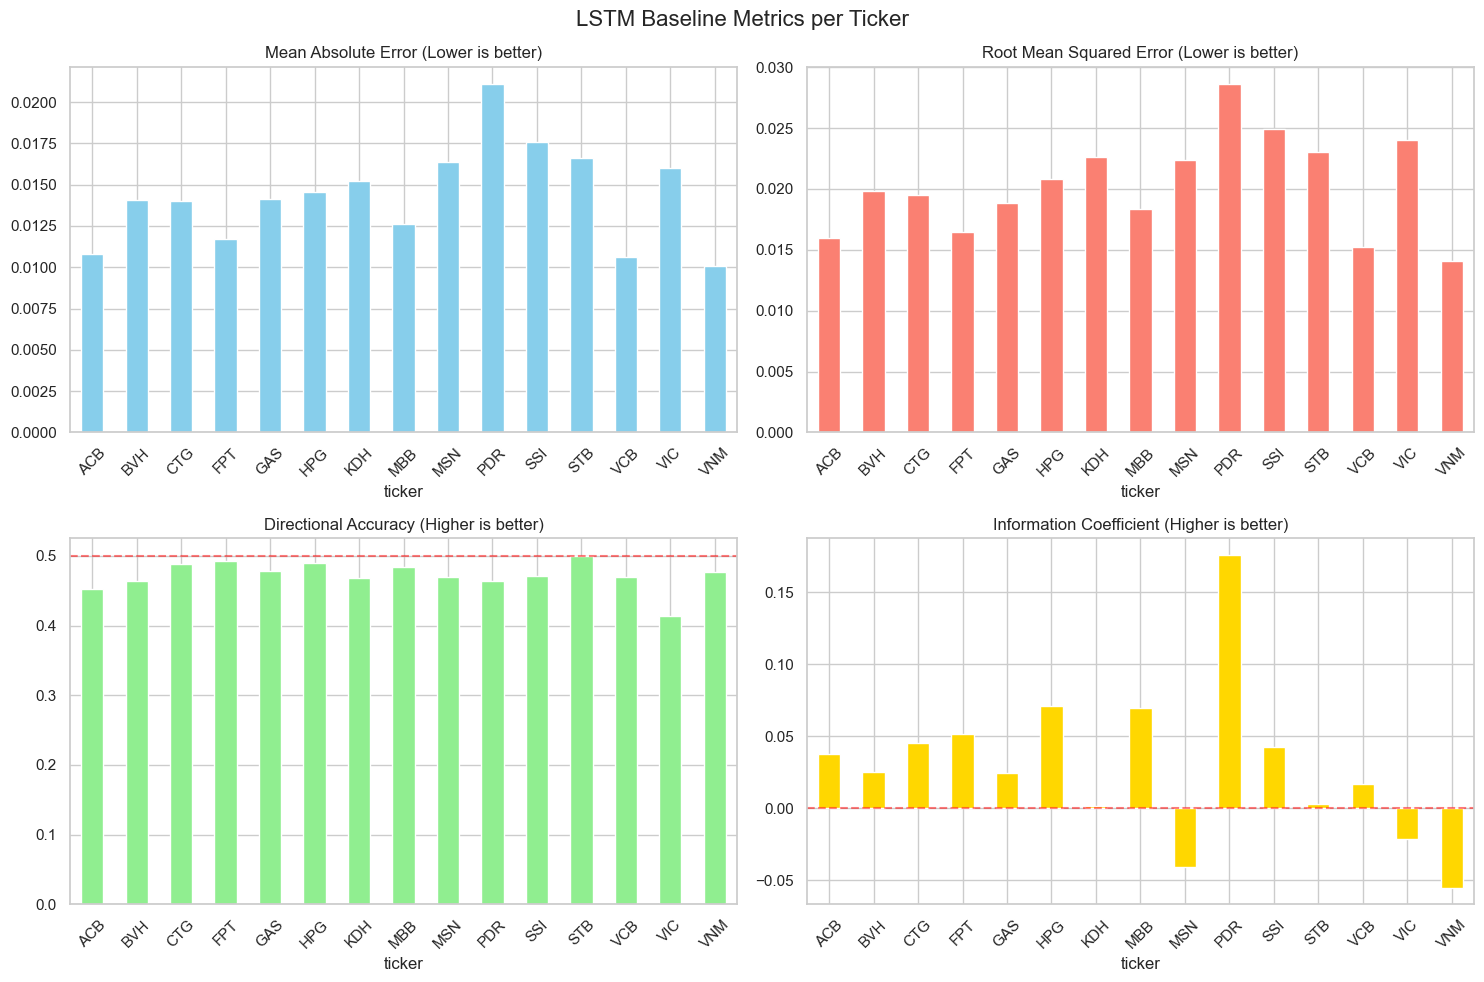

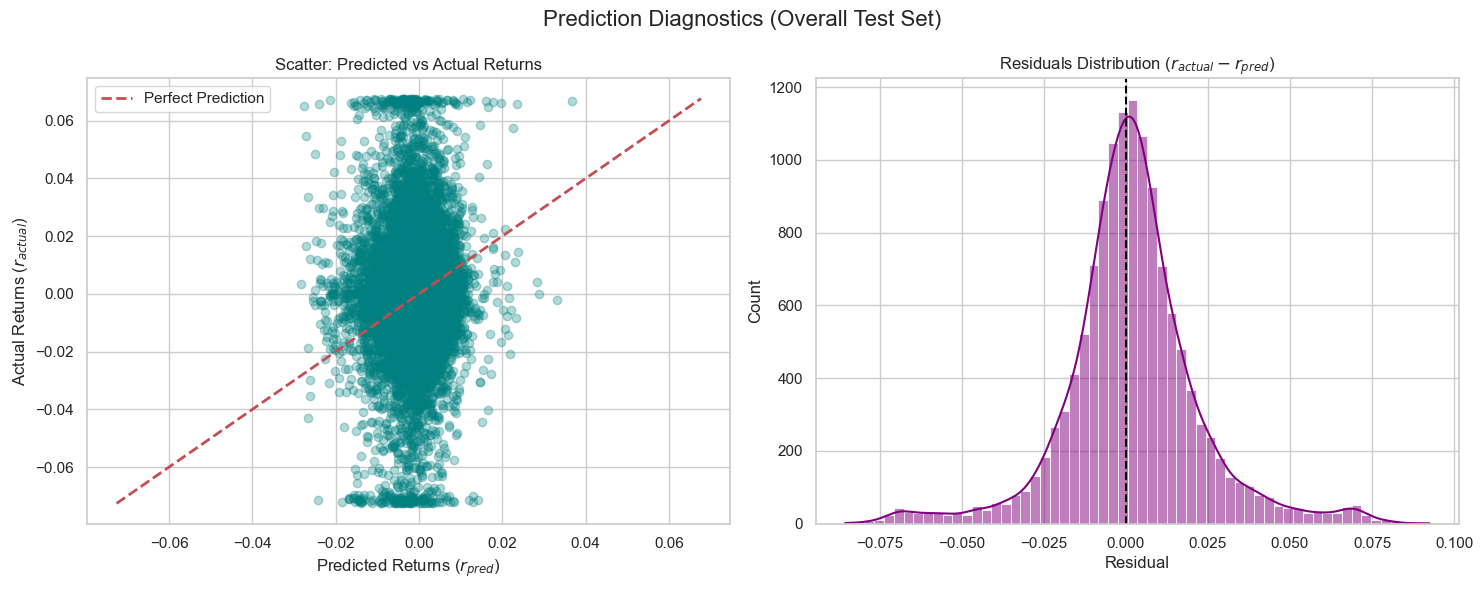

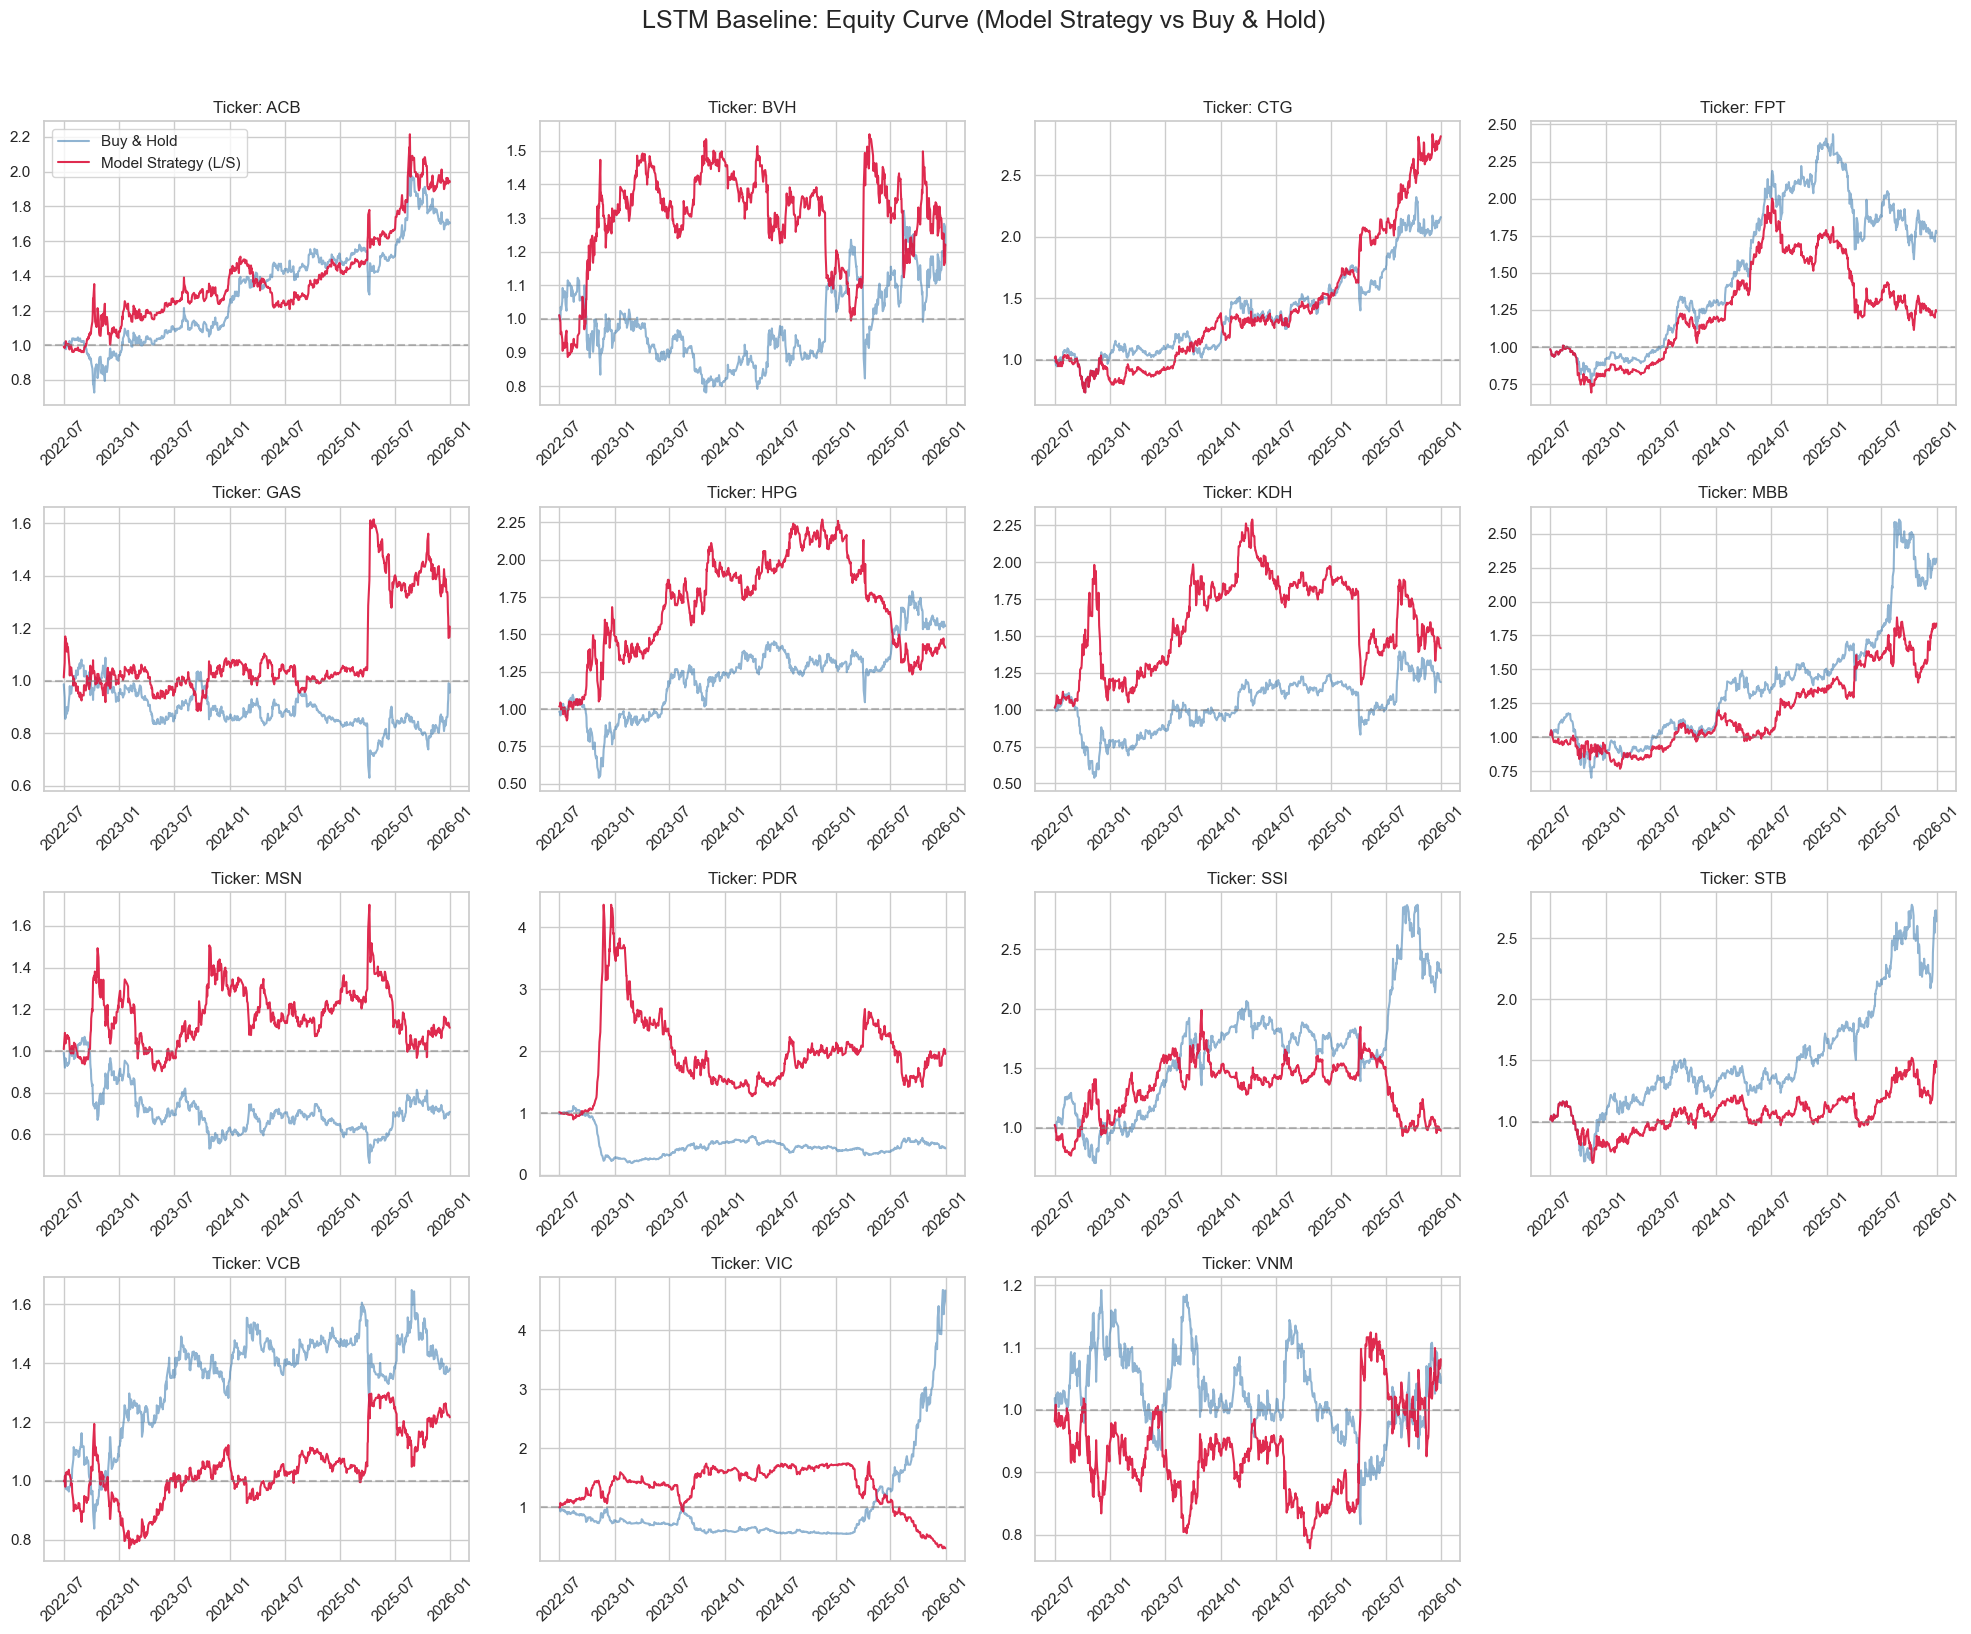

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import numpy as np

# Ensure styling
sns.set_theme(style="whitegrid")

# 1. Visualize Metrics per Ticker
if 'summary' in locals() and not summary.empty:
    # Lọc bỏ row OVERALL để vẽ biểu đồ cho từng mã
    df_plot = summary[summary['ticker'] != 'OVERALL'].set_index('ticker')
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('LSTM Baseline Metrics per Ticker', fontsize=16)
    
    # MAE
    df_plot[['MAE']].plot(kind='bar', ax=axes[0, 0], color='skyblue', legend=False)
    axes[0, 0].set_title('Mean Absolute Error (Lower is better)')
    axes[0, 0].tick_params(axis='x', rotation=45)
    
    # RMSE
    df_plot[['RMSE']].plot(kind='bar', ax=axes[0, 1], color='salmon', legend=False)
    axes[0, 1].set_title('Root Mean Squared Error (Lower is better)')
    axes[0, 1].tick_params(axis='x', rotation=45)
    
    # Directional Accuracy (DA)
    df_plot[['DA']].plot(kind='bar', ax=axes[1, 0], color='lightgreen', legend=False)
    axes[1, 0].set_title('Directional Accuracy (Higher is better)')
    axes[1, 0].axhline(0.5, color='red', linestyle='--', alpha=0.5) # Baseline random
    axes[1, 0].tick_params(axis='x', rotation=45)
    
    # Information Coefficient (IC)
    df_plot[['IC']].plot(kind='bar', ax=axes[1, 1], color='gold', legend=False)
    axes[1, 1].set_title('Information Coefficient (Higher is better)')
    axes[1, 1].axhline(0.0, color='red', linestyle='--', alpha=0.5)
    axes[1, 1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

# 2. Scatter & Residuals Overall
if 'results' in locals() and not results.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    fig.suptitle('Prediction Diagnostics (Overall Test Set)', fontsize=16)
    
    # Tính residuals
    results['residual'] = results['target'] - results['pred']
    
    # a. Scatter Plot
    ax1 = axes[0]
    ax1.scatter(results['pred'], results['target'], alpha=0.3, color='teal')
    
    # 45-degree reference line
    min_val = min(results['pred'].min(), results['target'].min())
    max_val = max(results['pred'].max(), results['target'].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
    
    ax1.set_title('Scatter: Predicted vs Actual Returns')
    ax1.set_xlabel('Predicted Returns ($r_{pred}$)')
    ax1.set_ylabel('Actual Returns ($r_{actual}$)')
    ax1.legend()
    
    # b. Residuals Distribution
    ax2 = axes[1]
    sns.histplot(results['residual'], bins=60, kde=True, color='purple', ax=ax2)
    ax2.axvline(0, color='black', linestyle='--', linewidth=1.5)
    ax2.set_title('Residuals Distribution ($r_{actual} - r_{pred}$)')
    ax2.set_xlabel('Residual')
    
    plt.tight_layout()
    plt.show()

# 3. Visualize Equity Curve (Strategy vs Buy & Hold) for each ticker
if 'results' in locals() and not results.empty:
    unique_tickers = sorted(results['ticker'].unique())
    n_tickers = len(unique_tickers)
    
    cols = 4 # Plot 4 tickers per row
    rows = (n_tickers + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    if not isinstance(axes, np.ndarray):
        axes = [axes]
    else:
        axes = axes.flatten()
        
    fig.suptitle('LSTM Baseline: Equity Curve (Model Strategy vs Buy & Hold)', fontsize=18, y=1.02)
    
    for i, ticker in enumerate(unique_tickers):
        ax = axes[i]
        
        # Lọc df theo ticker
        df_t = results[results['ticker'] == ticker].sort_values('Date').reset_index(drop=True)
        
        # Chiến lược giao dịch dựa trên tín hiệu: Long nếu pred > 0, Short nếu pred < 0
        signal = np.sign(df_t['pred'])
        
        # Tính lũy kế tỷ suất sinh lời
        strategy_returns = signal * df_t['target']
        bnh_returns = df_t['target']
        
        # Equity Curve = Lợi nhuận tích luỹ (giả sử vốn ban đầu mức 1.0)
        equity_strategy = np.exp(strategy_returns.cumsum())
        equity_bnh = np.exp(bnh_returns.cumsum())
        
        ax.plot(df_t['Date'], equity_bnh, label='Buy & Hold', color='steelblue', alpha=0.6, linewidth=1.5)
        ax.plot(df_t['Date'], equity_strategy, label='Model Strategy (L/S)', color='crimson', alpha=0.9, linewidth=1.5)
        
        ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
        
        ax.set_title(f"Ticker: {ticker}")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45)
        
        if i == 0:
            ax.legend(loc='upper left')
            
    # Hide any empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()